# code_196 · Good ordering does not establish probability reliability

**Book:** section 37.1. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_37_GUIDE.md), [execution evidence](../CHAPTER_37_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_196).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Probability and interval contracts identify fitting and calibration roles, uncertainty sources, assessment units and decision costs. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=7896;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
Darwin arm64 CPU; seed 7896


<a id="fit-models-and-calibrate-separately"></a>
 ## Fit two actual probability models and calibrate on separate buildings
 Generate independent source 1,000, calibration 600 and final 600 buildings, one record each. Four features determine a nonlinear actionable-finding probability; outcomes remain noisy. Fit a 100-iteration native histogram classifier and an original 4→16→1 Tanh neural classifier with 600 Adam updates. The latter returns a validated typed record containing event name, bounded probability and binary decision; schema validity is not evidence of calibration and this is not a pretrained language-model benchmark. Deliberately multiply each source-fitted model's logits by two to create an explicit overconfidence stress condition. For each model, fit a positive scalar temperature by calibration log loss only. Temperature changes probability values while preserving each model's ranking and its zero-logit decision. Final outcomes assess all fixed routes without choosing a temperature.


In [2]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score,log_loss,brier_score_loss
from scipy.optimize import minimize_scalar
def cohort(n):
    x=rng.normal(size=(n,4));p=expit(1.4*x[:,0]-.8*x[:,1]+.7*x[:,2]*x[:,3]-.5);return x,rng.binomial(1,p)
xs,ys=cohort(1000);xc,yc=cohort(600);xf,yf=cohort(600);boost=HistGradientBoostingClassifier(max_iter=100,max_depth=3,learning_rate=.08,early_stopping=False,random_state=SEED).fit(xs,ys);net=nn.Sequential(nn.Linear(4,16),nn.Tanh(),nn.Linear(16,1));opt=torch.optim.Adam(net.parameters(),lr=.01,weight_decay=.001);tx=torch.tensor(xs);ty=torch.tensor(ys[:,None],dtype=torch.float64)
for _ in range(600):opt.zero_grad();loss=nn.functional.binary_cross_entropy_with_logits(net(tx),ty);loss.backward();opt.step()
def neural_logits(x):
    with torch.no_grad():return net(torch.tensor(x)).numpy().ravel()
logits={'Boost':(2*boost.decision_function(xc),2*boost.decision_function(xf)),'Typed neural':(2*neural_logits(xc),2*neural_logits(xf))};temperature={};scores={};pred={}
def typed_records(p):
    records=[{'event':'actionable_finding','probability':float(v),'decision':bool(v>=.5)} for v in p];assert all(set(r)=={'event','probability','decision'} and 0<=r['probability']<=1 for r in records);return records
for name,(cal,final) in logits.items():
    fit=minimize_scalar(lambda logt:np.mean(np.logaddexp(0,cal/np.exp(logt))-yc*cal/np.exp(logt)),bounds=(-3,3),method='bounded');assert fit.success;T=float(np.exp(fit.x));temperature[name]=T
    for route,p in [('Stress raw',expit(final)),('Calibrated',expit(final/T))]:
        key=f'{name}: {route}';pred[key]=p;scores[key]={'Brier':float(brier_score_loss(yf,p)),'log_loss':float(log_loss(yf,p)),'AUC':float(roc_auc_score(yf,p)),'probability_variance':float(np.var(p)),'mean_probability':float(p.mean()),'positive_class_mean_probability':float(p[yf==1].mean()),'negative_class_mean_probability':float(p[yf==0].mean())}
    assert np.isclose(scores[f'{name}: Stress raw']['AUC'],scores[f'{name}: Calibrated']['AUC']);assert np.array_equal(np.argsort(expit(final),kind='stable'),np.argsort(expit(final/T),kind='stable'))
records=typed_records(pred['Typed neural: Calibrated']);RESULTS.update(building_roles=[1000,600,600],raw_logit_stress_multiplier=2,temperature=temperature,probability_scores=scores,typed_records_validated=len(records),typed_record_schema_is_not_calibration=True);display(pd.DataFrame(scores).T)


,Brier,log_loss,AUC,probability_variance,mean_probability,positive_class_mean_probability,negative_class_mean_probability
Boost: Stress raw,0.200623,0.665050,0.794837,0.138349,0.419267,0.640717,0.269573
Boost: Calibrated,0.180979,0.536263,0.794837,0.061787,0.432808,0.584460,0.330295
Typed neural: Stress raw,0.198529,0.659096,0.807343,0.147302,0.416911,0.651969,0.258017
Typed neural: Calibrated,0.175454,0.520369,0.807343,0.069576,0.433081,0.601257,0.319397


<a id="reliability-and-discrimination"></a>
 ## Preserve small-bin uncertainty and unchanged ordering
 Use ten predeclared equal-width bins for positive-event reliability. Report bin count, mean quoted event probability, observed event frequency and a 95% Wilson interval for that frequency; empty bins are explicit. These are per-bin descriptive intervals under independent buildings, not a simultaneous band or uncertainty in the fitted model. ECE is a bin-dependent plugin summary, not a proper score and not a calibration certificate. Also report class-conditional probability means as discrimination diagnostics: conditioning on true class changes the question and is not a demand that every positive record have probability one. Visual A compares reliability and the same booster predictions sorted by raw risk, showing that rescaling leaves order unchanged while moving the probability values.


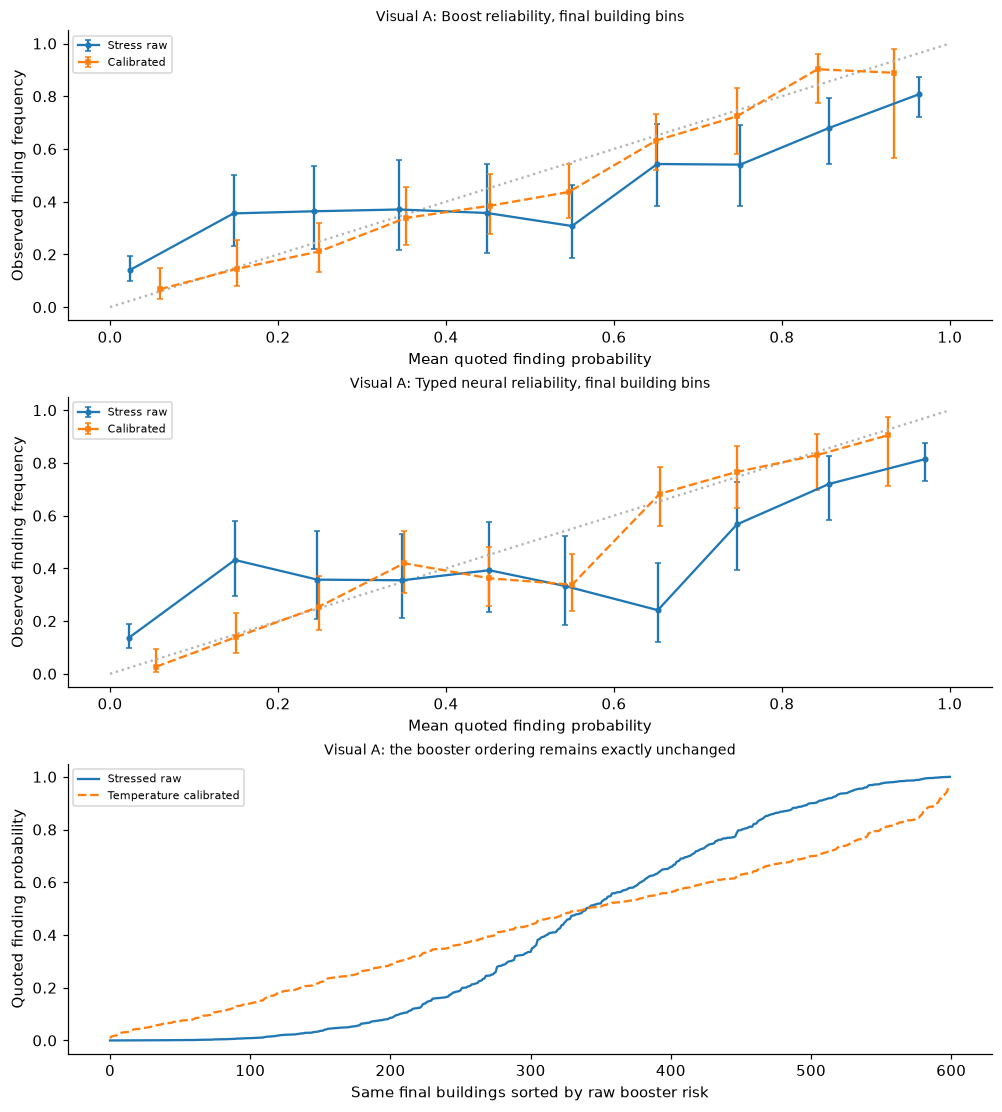

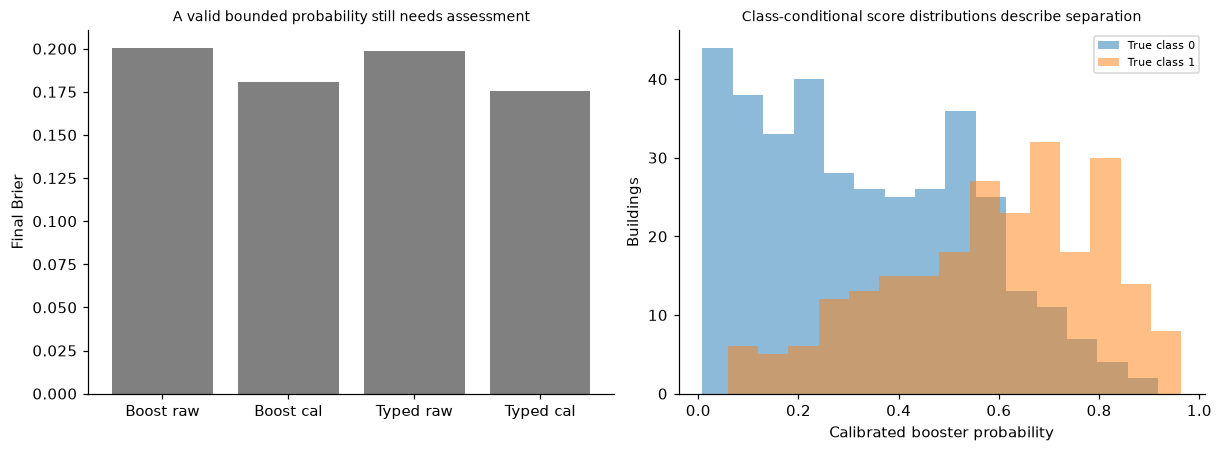

In [3]:
def reliability(p):
    bins=np.minimum((p*10).astype(int),9);out=[]
    for b in range(10):
        m=bins==b;n=int(m.sum())
        if n:
            f=float(yf[m].mean());z=1.959963984540054;den=1+z*z/n;centre=(f+z*z/(2*n))/den;half=z*np.sqrt(f*(1-f)/n+z*z/(4*n*n))/den;out.append({'bin':b,'n':n,'mean_probability':float(p[m].mean()),'frequency':f,'Wilson95':[centre-half,centre+half]})
        else:out.append({'bin':b,'n':0,'mean_probability':None,'frequency':None,'Wilson95':None})
    return out
tables={key:reliability(p) for key,p in pred.items()};ece={key:float(sum(r['n']/600*abs(r['mean_probability']-r['frequency']) for r in rows if r['n'])) for key,rows in tables.items()};assert all(sum(r['n'] for r in rows)==600 for rows in tables.values());assert all(0<=r['Wilson95'][0]<=r['Wilson95'][1]<=1 for rows in tables.values() for r in rows if r['n']);RESULTS.update(final_prevalence=float(yf.mean()),reliability_bins=tables,plugin_ECE=ece,bin_intervals_not_simultaneous=True)
fig,axes=plt.subplots(3,1,figsize=(9,10))
for ax,name in zip(axes[:2],['Boost','Typed neural']):
    for route,style in [('Stress raw','o-'),('Calibrated','s--')]:
        rows=[r for r in tables[f'{name}: {route}'] if r['n']];x=np.array([r['mean_probability'] for r in rows]);y=np.array([r['frequency'] for r in rows]);interval=np.array([r['Wilson95'] for r in rows]);ax.errorbar(x,y,yerr=np.array([y-interval[:,0],interval[:,1]-y]),fmt=style,markersize=3,capsize=2,label=route)
    ax.plot([0,1],[0,1],color='.7',linestyle=':');ax.set(xlabel='Mean quoted finding probability',ylabel='Observed finding frequency',title='Visual A: '+name+' reliability, final building bins');ax.legend(fontsize=7)
order=np.argsort(pred['Boost: Stress raw']);axes[2].plot(pred['Boost: Stress raw'][order],label='Stressed raw');axes[2].plot(pred['Boost: Calibrated'][order],'--',label='Temperature calibrated');axes[2].set(xlabel='Same final buildings sorted by raw booster risk',ylabel='Quoted finding probability',title='Visual A: the booster ordering remains exactly unchanged');axes[2].legend(fontsize=7);plt.show();fig,axes=plt.subplots(1,2,figsize=(11,4));names=list(scores);xx=np.arange(4);axes[0].bar(xx,[scores[k]['Brier'] for k in names],color='.5');axes[0].set(xticks=xx,xticklabels=['Boost raw','Boost cal','Typed raw','Typed cal'],ylabel='Final Brier',title='A valid bounded probability still needs assessment');axes[1].hist(pred['Boost: Calibrated'][yf==0],bins=15,alpha=.5,label='True class 0');axes[1].hist(pred['Boost: Calibrated'][yf==1],bins=15,alpha=.5,label='True class 1');axes[1].set(xlabel='Calibrated booster probability',ylabel='Buildings',title='Class-conditional score distributions describe separation');axes[1].legend(fontsize=7);plt.show()


In [4]:
summary={'example_id':'code_196','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual boosted classifier and original neural typed probability interface', 'independent positive-temperature calibration with unchanged ranking', 'fixed-bin reliability Wilson intervals Brier log loss and sharpness', 'class-conditional score checks separated from calibration definitions'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual boosted classifier and original neural typed probability interface", "independent positive-temperature calibration with unchanged ranking", "fixed-bin reliability Wilson intervals Brier log loss and sharpness", "class-conditional score checks separated from calibration definitions"], "elapsed_seconds": 1.215, "example_id": "code_196", "hardware": "Darwin arm64 CPU", "results": {"bin_intervals_not_simultaneous": true, "building_roles": [1000, 600, 600], "final_prevalence": 0.4033333333333333, "plugin_ECE": {"Boost: Calibrated": 0.0397976094117098, "Boost: Stress raw": 0.1434606699822157, "Typed neural: Calibrated": 0.05420477512181288, "Typed neural: Stress raw": 0.14976961750934145}, "probability_scores": {"Boost: Calibrated": {"AUC": 0.7948370192529665, "Brier": 0.1809794424364092, "log_loss": 0.536262515382947, "mean_probability": 0.43280831547264287, "negative_class_mean_probability": 0.33029547903945805, "positive_class_mean